## Experiment B

This notebooks run the follwoing expriments on `Aljolfey's Archived Dataset`:
1. Model tuning, training and testing on full dataset
2. Model tuning, training and testing on sample with present JavaScript
3. Ablation study


In [1]:
# library imports
import logging
import os
import sys
import numpy as np
import pandas as pd
import json

from sklearn.preprocessing import MinMaxScaler
from tokenizers import Tokenizer, pre_tokenizers
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_score,
                             recall_score, roc_auc_score, roc_curve)

In [2]:
# directory mapping
FEATURES_DIR = "DB_features"
MODELS_DIR = "models_final_E2"
RESULTS_DIR = "results_final_E2"
LOG_PATH = "logs/model_training_E2.log"

features_path = os.path.join(FEATURES_DIR, "features.csv")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs("logs", exist_ok=True)

features_path = os.path.join(FEATURES_DIR, "features.csv")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs("logs", exist_ok=True)

In [3]:
# logging configuration
stream_handler = logging.StreamHandler(sys.stdout)
stream_handler.flush = sys.stdout.flush
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s",
    handlers=[logging.FileHandler(LOG_PATH), stream_handler],
    force=True,
)
log = logging.getLogger(__name__)

In [4]:
# loading dataset
df = pd.read_csv(features_path)
df.head()

,sample_id,source,hostname,url_length,url_dot_count,url_hyphen_count,url_underscore_count,url_slash_count,url_digit_count,url_has_ip_address,...,tfidf_bpe_92__bpe_62,tfidf_bpe_93,tfidf_bpe_94,tfidf_bpe_95,tfidf_bpe_96,tfidf_bpe_97,tfidf_bpe_98,tfidf_bpe_99,split,label
0,7a40aed624d980c7,D1,barcindia.co.in,22,2,0,0,2,0,0,...,0.0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,train,0
1,e490e7c4c454cfbf,D1,ace.co.uk,16,2,0,0,2,0,0,...,0.0,0.000000,0.000000,0.00000,0.000000,0.212537,0.048059,0.000000,train,0
2,a0fb5d8de1d9789b,D1,autabuy.com,18,1,0,0,2,0,0,...,0.0,0.000519,0.000567,0.00437,0.001471,0.000000,0.493166,0.000000,train,0
3,e6fceaf4e4c5af99,D1,bohol.tv,29,2,0,0,4,0,0,...,0.0,0.000000,0.000000,0.00000,0.000000,0.000000,0.133471,0.000000,train,1
4,fbe074508f92b45a,D1,elplanmedicopr.com,25,1,0,0,2,0,0,...,0.0,0.140722,0.000000,0.00000,0.000000,0.000000,0.027590,0.112813,train,1


### Data Analysis

In [5]:
# url and HTML feature correlation
url_and_html_cols = [c for c in df.columns if c.startswith("url_") or c.startswith("html_")]
url_and_html_cols.append("label")
url_and_html_cols

['url_length',
 'url_dot_count',
 'url_hyphen_count',
 'url_underscore_count',
 'url_slash_count',
 'url_digit_count',
 'url_has_ip_address',
 'url_has_https',
 'url_subdomain_count',
 'url_query_length',
 'url_entropy',
 'url_special_char_ratio',
 'html_script_link_ratio',
 'html_css_link_ratio',
 'html_image_link_ratio',
 'html_anchor_link_ratio',
 'html_empty_link_ratio',
 'html_anchor_without_href_ratio',
 'html_total_hyperlinks',
 'html_internal_link_ratio',
 'html_external_link_ratio',
 'html_external_internal_ratio',
 'html_total_forms',
 'html_missing_title',
 'html_hidden_elements_count',
 'html_text_to_tag_ratio',
 'label']

In [6]:
df_url_html = df[url_and_html_cols]
df_url_html.head()

,url_length,url_dot_count,url_hyphen_count,url_underscore_count,url_slash_count,url_digit_count,url_has_ip_address,url_has_https,url_subdomain_count,url_query_length,...,html_anchor_without_href_ratio,html_total_hyperlinks,html_internal_link_ratio,html_external_link_ratio,html_external_internal_ratio,html_total_forms,html_missing_title,html_hidden_elements_count,html_text_to_tag_ratio,label
0,22,2,0,0,2,0,0,0,1,0,...,0.000000,64,0.468750,0.125000,0.266667,2,0,0,6.149856,0
1,16,2,0,0,2,0,0,0,1,0,...,0.000000,2,0.000000,0.500000,0.000000,1,0,1,14.225806,0
2,18,1,0,0,2,0,0,0,0,0,...,0.005571,359,0.729805,0.033426,0.045802,3,0,3,11.068257,0
3,29,2,0,0,4,0,0,0,0,0,...,0.000000,48,0.375000,0.145833,0.388889,1,0,0,3.827160,1
4,25,1,0,0,2,0,0,0,0,0,...,0.000000,30,0.500000,0.100000,0.200000,1,0,0,4.261261,1


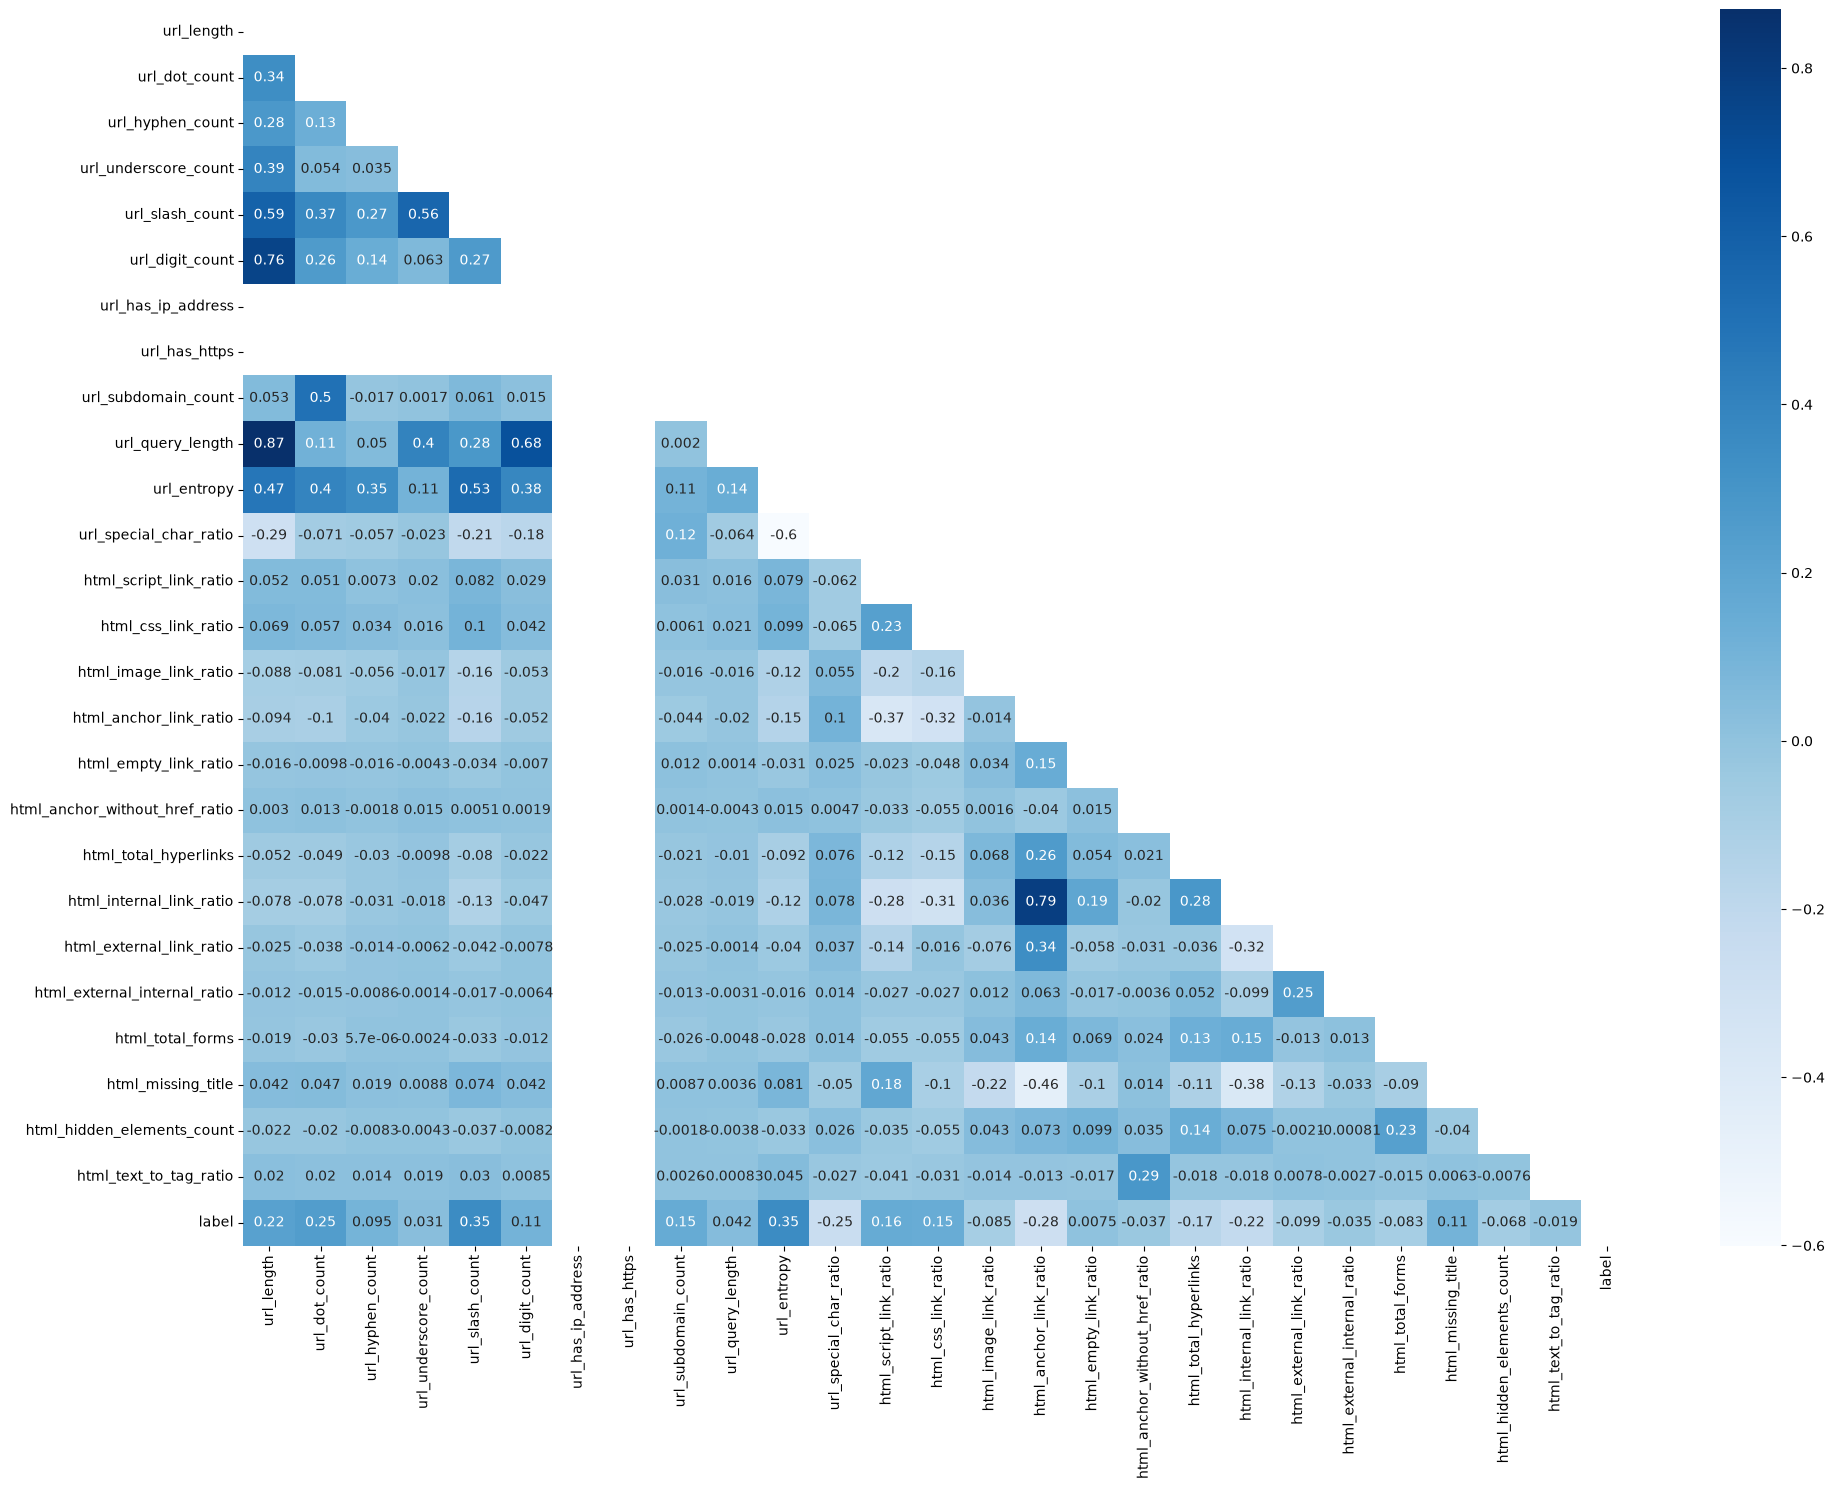

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

df_url_html_corr = df_url_html.corr()
mask = np.triu(df_url_html_corr)

plt.figure(figsize=(20, 15))
sns.heatmap(df_url_html_corr, mask=mask, cmap="Blues", annot=True, )
plt.tight_layout()
plt.show()

#### Presence of JS within dataset

In [8]:
df["has_js_sequence"] = (df["js_n_inline_scripts"] == 0).map({True: 1, False: 0})

In [9]:
js_presence_by_label = pd.crosstab(
    df["has_js_sequence"], df["label"], normalize="index"
)
# log.info("has_js_sequence vs. label (row-normalized):\n"
        #  f"{js_presence_by_label}")
js_presence_by_label

label,0,1
has_js_sequence,,
0,0.686293,0.313707
1,0.407537,0.592463


### Model hyperparameter tuning

In [10]:
# feature groups
url_cols = [c for c in df.columns if c.startswith("url_")]
html_cols = [c for c in df.columns if c.startswith("html_")]
js_cols = [c for c in df.columns if c.startswith("js_") or c.startswith("tfidf_bpe_")]
feature_cols = url_cols + html_cols + js_cols
print("url:", len(url_cols), "| html:", len(html_cols), "| js:", len(js_cols), "| total:", len(feature_cols))

df[feature_cols] = df[feature_cols].fillna(0)

# use the train/test split that is already in the csv
train_df = df[df["split"] == "train"].reset_index(drop=True)
train_df = train_df[feature_cols]

test_df = df[df["split"] == "test"].reset_index(drop=True)
test_df = test_df[feature_cols]

y_train = df[df['split'] == 'train']["label"].values
y_test = df[df['split'] == 'test']["label"].values

y = df['label']
X = df[feature_cols]
print("train:", len(train_df), "| test:", len(test_df))

url: 12 | html: 14 | js: 254 | total: 280
train: 21651 | test: 5413


In [11]:
# min-max scaling fitted on the training split only
scaler = MinMaxScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

In [12]:
# grid search runs on a stratified subsample of the training split
train_df_search = train_df.copy()
train_df_search = pd.concat([train_df_search, pd.Series(y_train, name='label')], axis=1)

SEARCH_ROWS = 0.25

search_df, _ = train_test_split(train_df_search, train_size=SEARCH_ROWS,
                                stratify=train_df_search["label"], random_state=42)

X_search = scaler.transform(search_df[feature_cols])
y_search = search_df["label"].values
print(f"rows used for the grid search: {len(search_df)}, {SEARCH_ROWS*100:.2f}%")

rows used for the grid search: 5412, 25.00%


In [13]:
# model hyperparameters
dt_params = {"max_depth": [5, 10, 15, None],
             "min_samples_split": [2, 5, 10]}

rf_params = {"n_estimators": [100, 200, 300],
             "max_features": ['sqrt', 'log2', None]}

xgb_params = {"learning_rate": [0.01, 0.1, 0.2, 0.3],
             "max_depth": [3, 6, 9]}

#### Grid search

In [14]:
SEED = 42

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"f1_macro": "f1_macro", 
           "precision": "precision", 
           "recall": "recall",
           "accuracy": "accuracy",
           "roc_auc": "roc_auc", 
           "mcc": "matthews_corrcoef"}

searches = {
    "decision_tree": (DecisionTreeClassifier(random_state=SEED), dt_params),
    "random_forest": (RandomForestClassifier(random_state=SEED), rf_params),
    "xgboost": (XGBClassifier(random_state=SEED), xgb_params),
}

In [15]:
# tuning
import time

def model_tuning(searches, X_search, y_search, scoring, cv, refit="f1_macro"):
    best_params = {}
    tuning_rows = []

    for name, (model, grid) in searches.items():
        search = GridSearchCV(model, grid, scoring=scoring, cv=cv, refit=refit)
        t0 = time.perf_counter()
        search.fit(X_search, y_search)
        search_time = time.perf_counter() - t0

        # Extract standard deviation for the best index
        best_idx = search.best_index_
        best_std = search.cv_results_[f"std_test_{refit}"][best_idx]

        best_params[name] = search.best_params_
        pd.DataFrame(search.cv_results_).to_csv(f"{RESULTS_DIR}/cv_results_{name}_E2.csv", index=False)
        
        tuning_rows.append({
            "model": name, 
            "best_cv_f1": search.best_score_,
            "best_cv_f1_std": best_std,  # <--- Added std here
            "search_time_s": search_time, 
            "best_params": search.best_params_
        })
        
        print(f"{name} | best CV F1: {search.best_score_:.4f} (+/- {best_std:.4f}) | {search.best_params_} | {search_time:.1f}s")

    # stacking classifier
    stack = StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **best_params["random_forest"])),
            ("xgb", XGBClassifier(random_state=SEED, n_jobs=-1, **best_params["xgboost"]))
        ],
        final_estimator=LogisticRegression(solver="saga", max_iter=5000, random_state=SEED),
        cv=5
    )

    lr_params = {
        'final_estimator__C': [0.01, 0.1, 1.0, 10.0],
        'final_estimator__l1_ratio': [0, 0.5, 1]
    }

    search = GridSearchCV(stack, lr_params, scoring=scoring, cv=cv, refit=refit, n_jobs=1)
    t0 = time.perf_counter()
    search.fit(X_search, y_search)
    search_time = time.perf_counter() - t0

    # Extract standard deviation for stacking
    best_idx = search.best_index_
    best_std = search.cv_results_[f"std_test_{refit}"][best_idx]

    best_params["stacking"] = search.best_params_

    pd.DataFrame(search.cv_results_).to_csv(f"{RESULTS_DIR}/cv_results_stacking_E2.csv", index=False)
    
    tuning_rows.append({
        "model": "stacking", 
        "best_cv_f1": search.best_score_,
        "best_cv_f1_std": best_std,
        "search_time_s": search_time, 
        "best_params": search.best_params_
    })
    
    print(f"stacking | best CV F1: {search.best_score_:.4f} (+/- {best_std:.4f}) | {search.best_params_} | {search_time:.1f}s")

    tuning_df = pd.DataFrame(tuning_rows)
    tuning_df.to_csv(f"{RESULTS_DIR}/tuning_summary_E2.csv", index=False)
    with open(f"{RESULTS_DIR}/best_params_E2.json", "w") as f:
        json.dump(best_params, f, indent=2)

    return tuning_df, best_params

tuning_df, best = model_tuning(searches, X_search, y_search, scoring, cv)
tuning_df

decision_tree | best CV F1: 0.7441 (+/- 0.0108) | {'max_depth': 5, 'min_samples_split': 10} | 9.8s
random_forest | best CV F1: 0.7847 (+/- 0.0125) | {'max_features': None, 'n_estimators': 300} | 592.7s
xgboost | best CV F1: 0.8007 (+/- 0.0162) | {'learning_rate': 0.2, 'max_depth': 6} | 40.1s
stacking | best CV F1: 0.7965 (+/- 0.0115) | {'final_estimator__C': 1.0, 'final_estimator__l1_ratio': 0.5} | 2554.2s


,model,best_cv_f1,best_cv_f1_std,search_time_s,best_params
0,decision_tree,0.744106,0.010832,9.848203,"{'max_depth': 5, 'min_samples_split': 10}"
1,random_forest,0.784657,0.012508,592.681007,"{'max_features': None, 'n_estimators': 300}"
2,xgboost,0.800716,0.016204,40.073312,"{'learning_rate': 0.2, 'max_depth': 6}"
3,stacking,0.796493,0.011515,2554.214288,"{'final_estimator__C': 1.0, 'final_estimator__..."


### Train and Test

In [16]:
models = {
    "decision_tree": DecisionTreeClassifier(random_state=SEED, **best["decision_tree"]),
    "random_forest": RandomForestClassifier(random_state=SEED, n_jobs=-1, **best["random_forest"]),
    "xgboost": XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **best["xgboost"]),
    "stacking": StackingClassifier(
        estimators=[("rf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **best["random_forest"])),
                    ("xgb", XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **best["xgboost"]))],
        final_estimator=LogisticRegression(solver="saga", max_iter=5000, random_state=SEED,
                                           C=best["stacking"]["final_estimator__C"],
                                           l1_ratio=best["stacking"]["final_estimator__l1_ratio"]),
        cv=5),
}

In [17]:
import joblib

def model_training(models, X, y,
                   X_train, X_test, 
                   y_train, y_test, 
                   scoring, set=""):
    results = []
    scores = {}

    for name, model in models.items():
        # multi-metric cross validation
        # cv_results = cross_validate(estimator=model,
                                    # X=X, y=y,
                                    # cv=5,
                                    # scoring=scoring,
                                    # return_estimator=True)

        # training time
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        train_time = time.perf_counter() - t0

        # inference time on the whole test set
        t0 = time.perf_counter()
        y_pred = model.predict(X_test)
        test_time = time.perf_counter() - t0

        if hasattr(model, "predict_proba"):
            scores[name] = model.predict_proba(X_test)[:, 1]

        # inference time for a single sample
        single = []
        for i in range(len(X_test)):
            t0 = time.perf_counter()
            model.predict(X_test[i:i + 1])
            single.append(time.perf_counter() - t0)

        joblib.dump(model, f"{MODELS_DIR}/{name}_E2{set}_full.joblib")

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
        model_summary = {
            "model": name,
            "n_features": X_train.shape[1],
            "n_train": len(y_train),
            "n_test": len(y_test),
            "train_time_s": round(train_time, 4),
            "test_set_s": round(test_time, 4),
            "infer_ms_per_sample": round(1000 * test_time / len(X_test), 4),
            "infer_ms_per_sample_avg": round(np.mean(single), 4),
            "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "test_accuracy": round(accuracy_score(y_test, y_pred), 4),
            "test_precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
            "test_recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
            "test_f1_macro": round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4),
            "test_f1_phishing": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "test_mcc": round(matthews_corrcoef(y_test, y_pred), 4),
            "test_roc_auc": (round(roc_auc_score(y_test, scores[name]), 4)
                if name in scores else np.nan
                ),
            }

        # extract mean and std for each metric
        # for metric in scoring.keys():
            # scores_list = cv_results[f'test_{metric}']
            # model_summary[f"cv_{metric}_mean"] = round(np.mean(scores_list), 4)
            # model_summary[f"cv_{metric}_std"] = round(np.std(scores_list), 4)
        results.append(model_summary)
        print(f"{name} training complete | Macro F1 {model_summary['test_f1_macro']} | training time {train_time:.4f} s")

    #joblib.dump(scaler, f"{MODELS_DIR}/scaler_full.joblib")
    results_df = pd.DataFrame(results)
    results_df.to_csv(f"{RESULTS_DIR}/full_feature_results_E2.csv", index=False)
    print(f"Models saved to --> {RESULTS_DIR}/full_feature_results_E2.csv")
    return results_df, scores

results_df, scores = model_training(models, X, y, X_train, X_test, y_train, y_test, scoring)
results_df

decision_tree training complete | Macro F1 0.7484 | training time 0.5002 s
random_forest training complete | Macro F1 0.8075 | training time 67.4749 s
xgboost training complete | Macro F1 0.8197 | training time 1.0493 s
stacking training complete | Macro F1 0.822 | training time 296.4584 s
Models saved to --> results_final_E2/full_feature_results_E2.csv


,model,n_features,n_train,n_test,train_time_s,test_set_s,infer_ms_per_sample,infer_ms_per_sample_avg,tn,fp,fn,tp,test_accuracy,test_precision,test_recall,test_f1_macro,test_f1_phishing,test_mcc,test_roc_auc
0,decision_tree,280,21651,5413,0.5002,0.0022,0.0004,0.0000,2812,583,678,1340,0.7670,0.6968,0.6640,0.7484,0.6800,0.4974,0.8278
1,random_forest,280,21651,5413,67.4749,0.0518,0.0096,0.0142,3015,380,574,1444,0.8238,0.7917,0.7156,0.8075,0.7517,0.6175,0.8907
2,xgboost,280,21651,5413,1.0493,0.0020,0.0004,0.0001,3034,361,535,1483,0.8345,0.8042,0.7349,0.8197,0.7680,0.6413,0.9053
3,stacking,280,21651,5413,296.4584,0.0441,0.0082,0.0139,3041,354,530,1488,0.8367,0.8078,0.7374,0.8220,0.7710,0.6461,0.9074


In [18]:
# plot style: muted, professional palette shared by every figure
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Colors extracted from your uploaded palette
LIGHT_SLATE = "#B8BFD6"  #[cite: 6]
MID_SLATE   = "#53607A"  #[cite: 6]
DEEP_NAVY   = "#19335A"  #[cite: 6]
SKY_BLUE    = "#8FC8EB"  #[cite: 6]
ROYAL_BLUE  = "#4675C0"  #[cite: 6]
INK         = "#2B2F36"
 
# One distinct, high-contrast color per model from the new palette
MODEL_COLORS = {
    "decision_tree": LIGHT_SLATE, 
    "random_forest": MID_SLATE, 
    "xgboost": ROYAL_BLUE, 
    "stacking": DEEP_NAVY
}

MODEL_STYLES = {"decision_tree": ":", "random_forest": "--", "xgboost": "-.", "stacking": "-"}
MODEL_LABELS = {"decision_tree": "Decision Tree", "random_forest": "Random Forest",
                "xgboost": "XGBoost", "stacking": "Stacking"}

# Sequential and diverging colormaps using the new theme colors
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_navy", ["#FFFFFF", LIGHT_SLATE, DEEP_NAVY])
DIV_CMAP = LinearSegmentedColormap.from_list("div_navy_brick", [SKY_BLUE, "#F7F7F7", DEEP_NAVY])

plt.rcParams.update({
    "figure.dpi": 300,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": "#9AA3AE",
    "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlepad": 12,
    "axes.grid": True, "grid.color": "#E3E7EC", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False,
})

2026-10-08 20:06:18,194 [WARNING] findfont: Failed to find font weight semibold, now using 700.


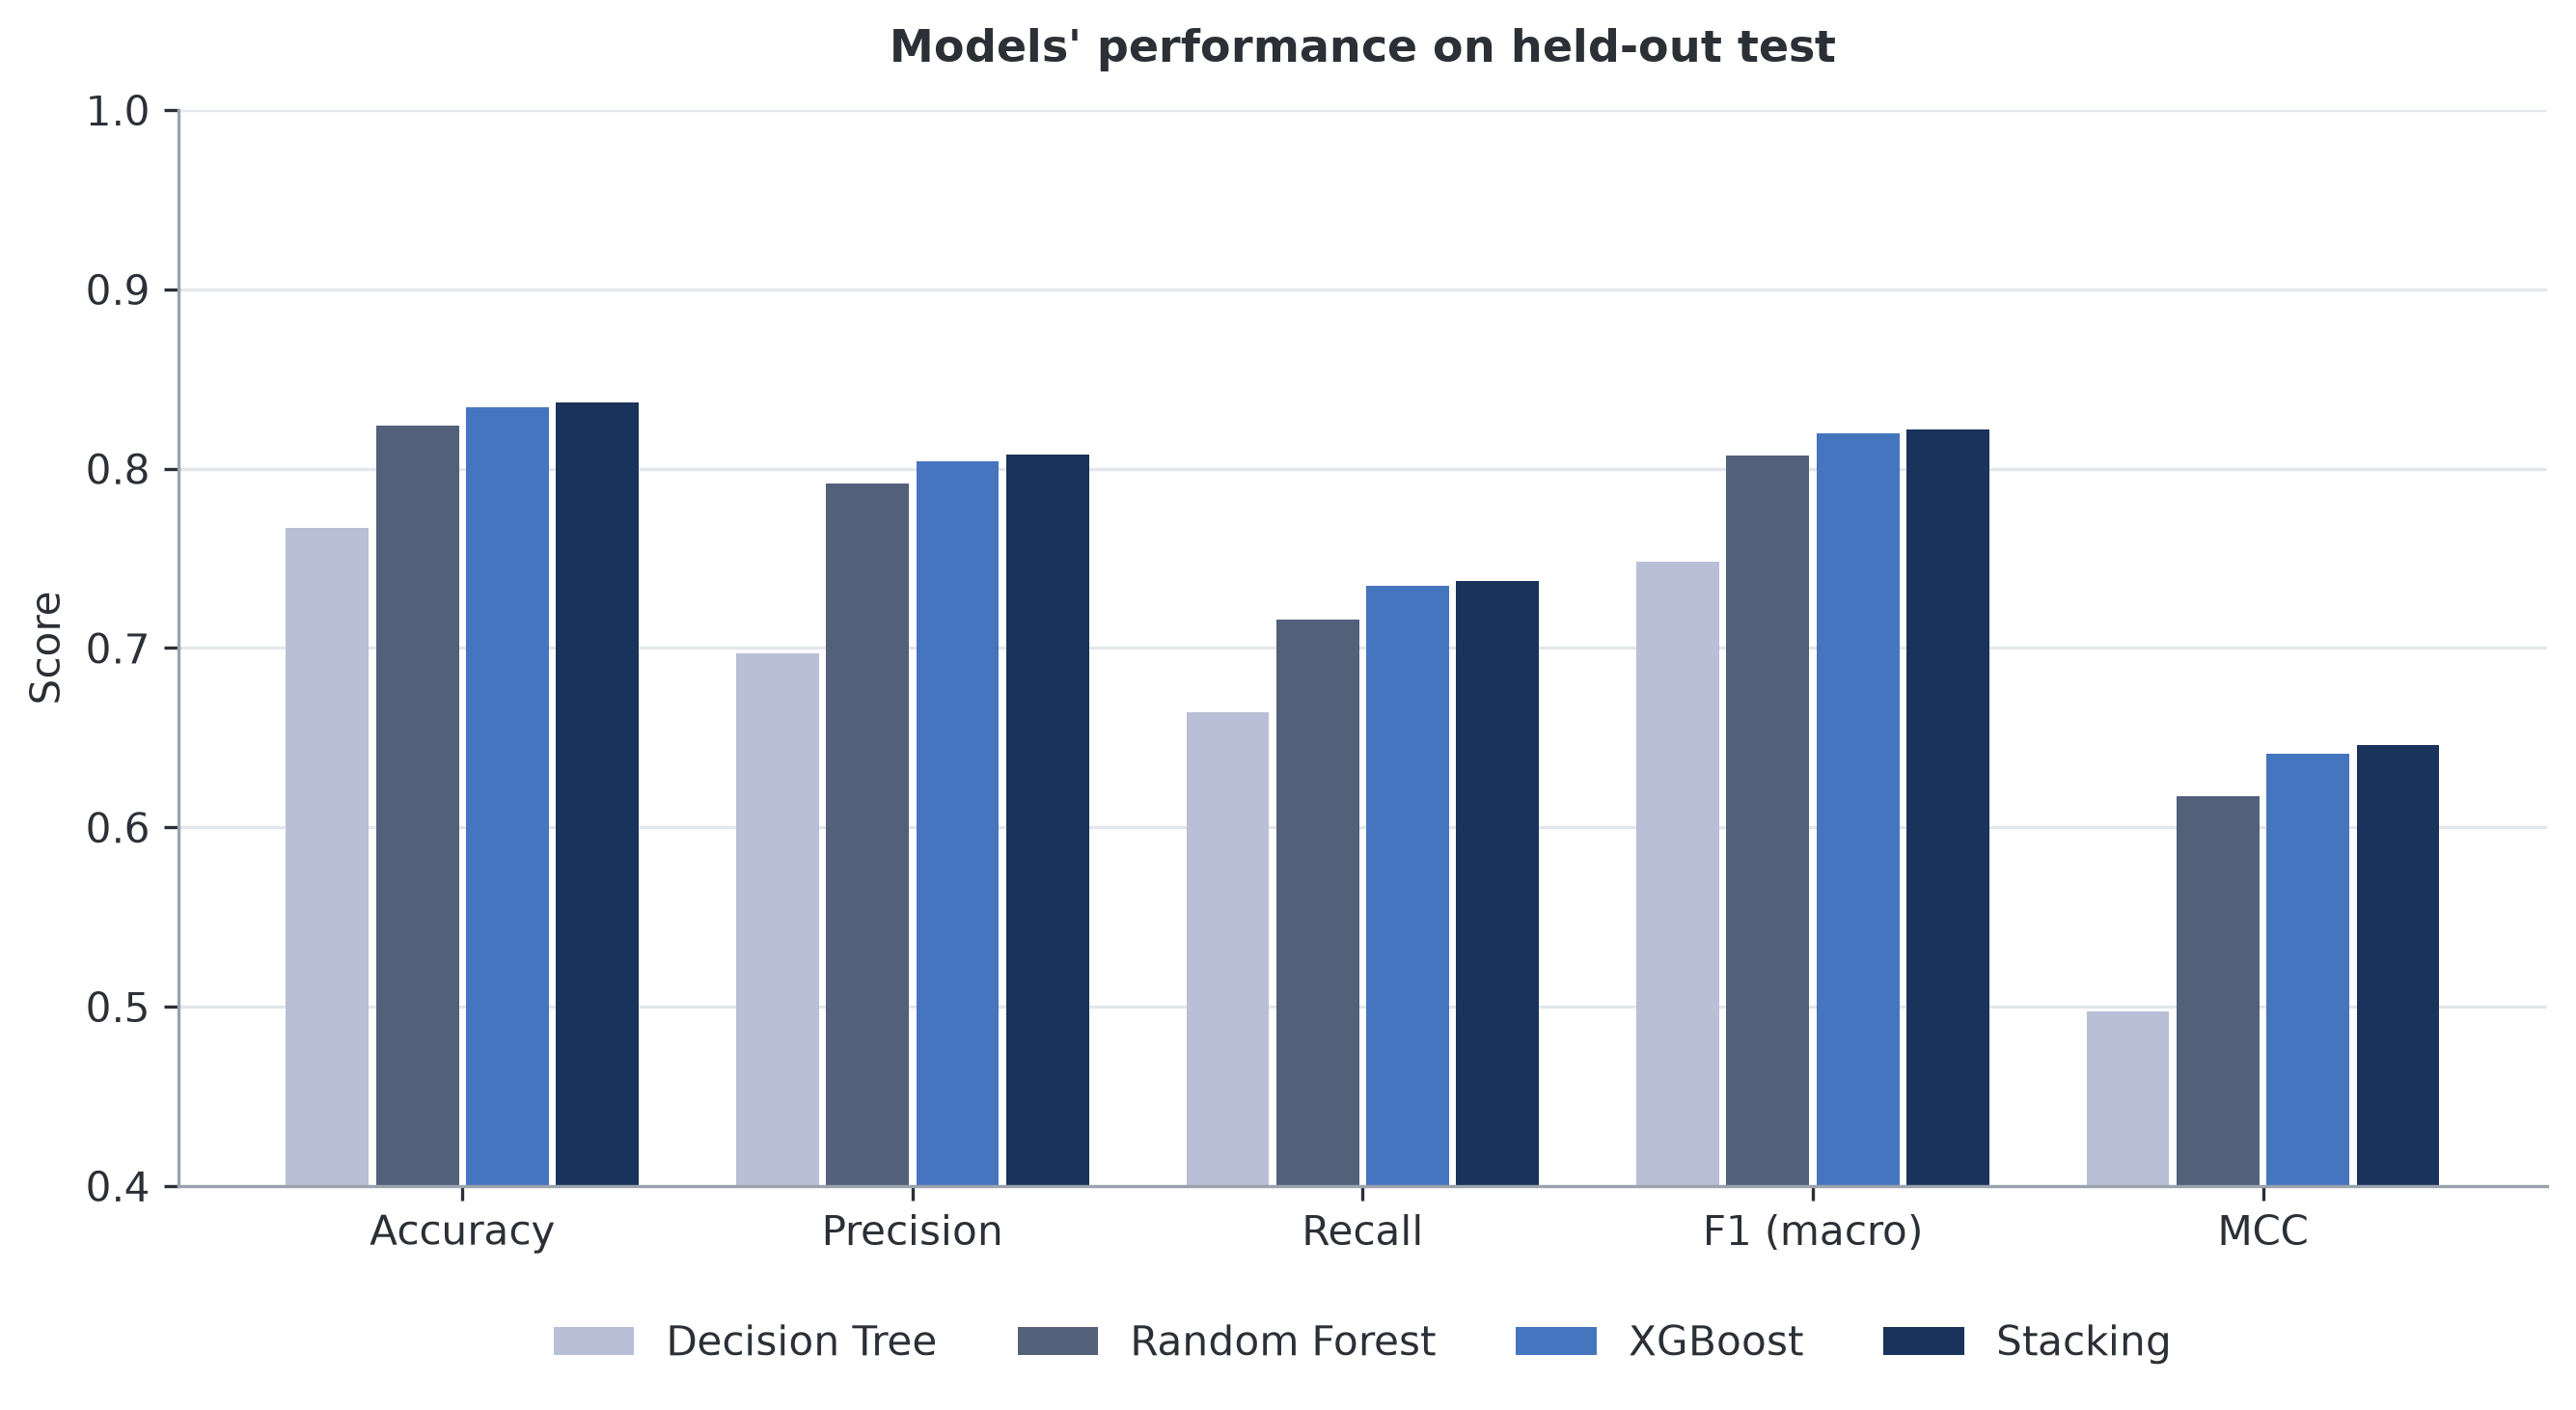

In [ ]:
# figure 1: cross-validated metrics (5-fold, mean +/- SD)
metric_cols = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall",
               "f1_macro": "F1 (macro)", "mcc": "MCC"}
res = results_df.set_index("model")
n_models, n_metrics = len(res), len(metric_cols)
bar_w = 0.8 / n_models

fig, ax = plt.subplots(figsize=(9, 5))
for i, (name, row) in enumerate(res.iterrows()):
    xs = np.arange(n_metrics) + (i - (n_models - 1) / 2) * bar_w
    ax.bar(xs, [row[f"test_{m}"] for m in metric_cols], width=bar_w * 0.92,
           color=MODEL_COLORS[name], label=MODEL_LABELS[name])
ax.set_xticks(np.arange(n_metrics))
ax.set_xticklabels(metric_cols.values())
ax.set_ylim(0.4000, 1.0000)
ax.set_ylabel("Score")
ax.set_title("Models' performance on held-out test")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", ncol=n_models, bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()

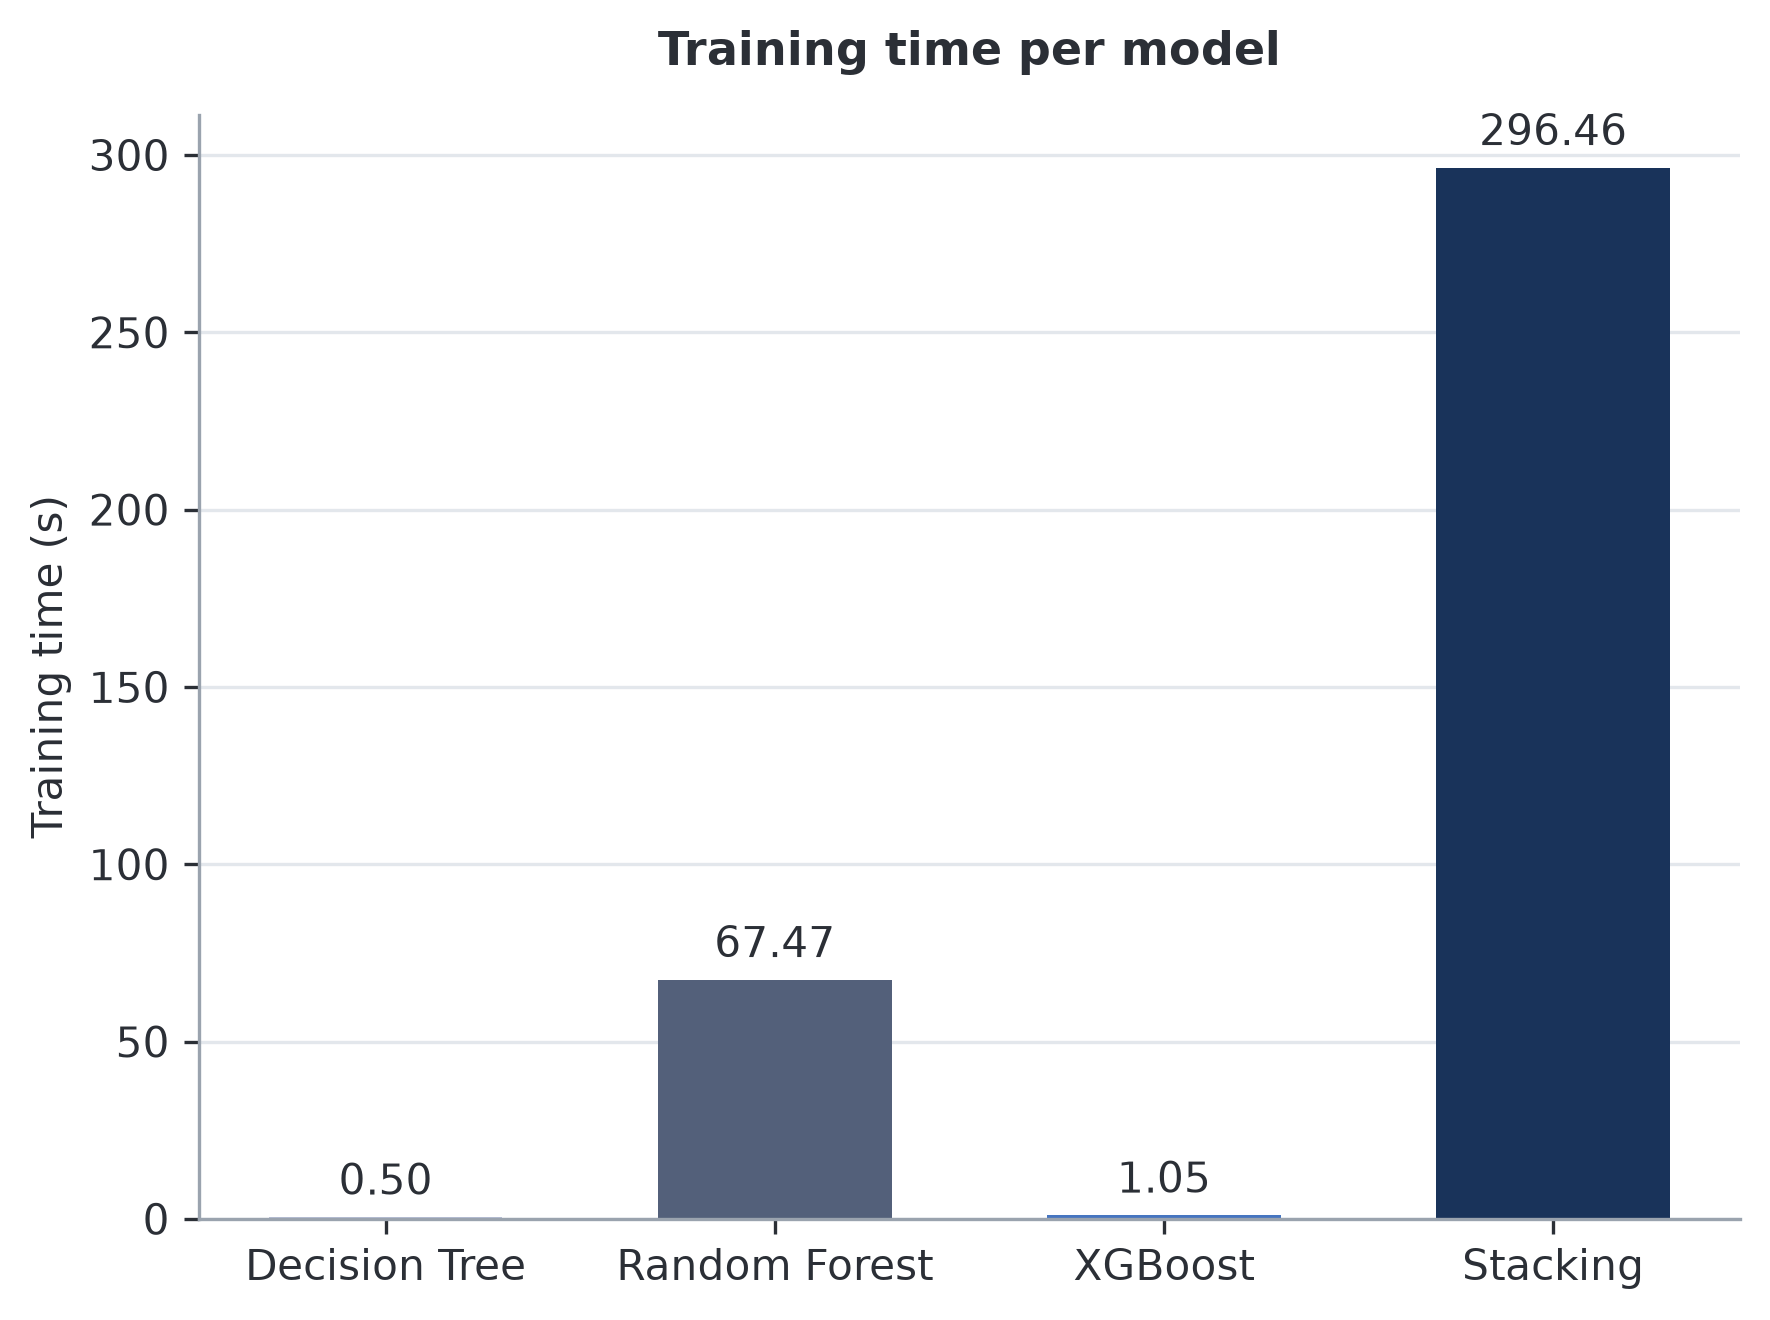

In [20]:
# figure 2: training time
fig, ax = plt.subplots(figsize=(6, 4.5))
times = results_df.set_index("model")["train_time_s"]
bars = ax.bar([MODEL_LABELS[m] for m in times.index], times.values,
              color=[MODEL_COLORS[m] for m in times.index], width=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, color=INK)
ax.set_ylabel("Training time (s)")
ax.set_title("Training time per model")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

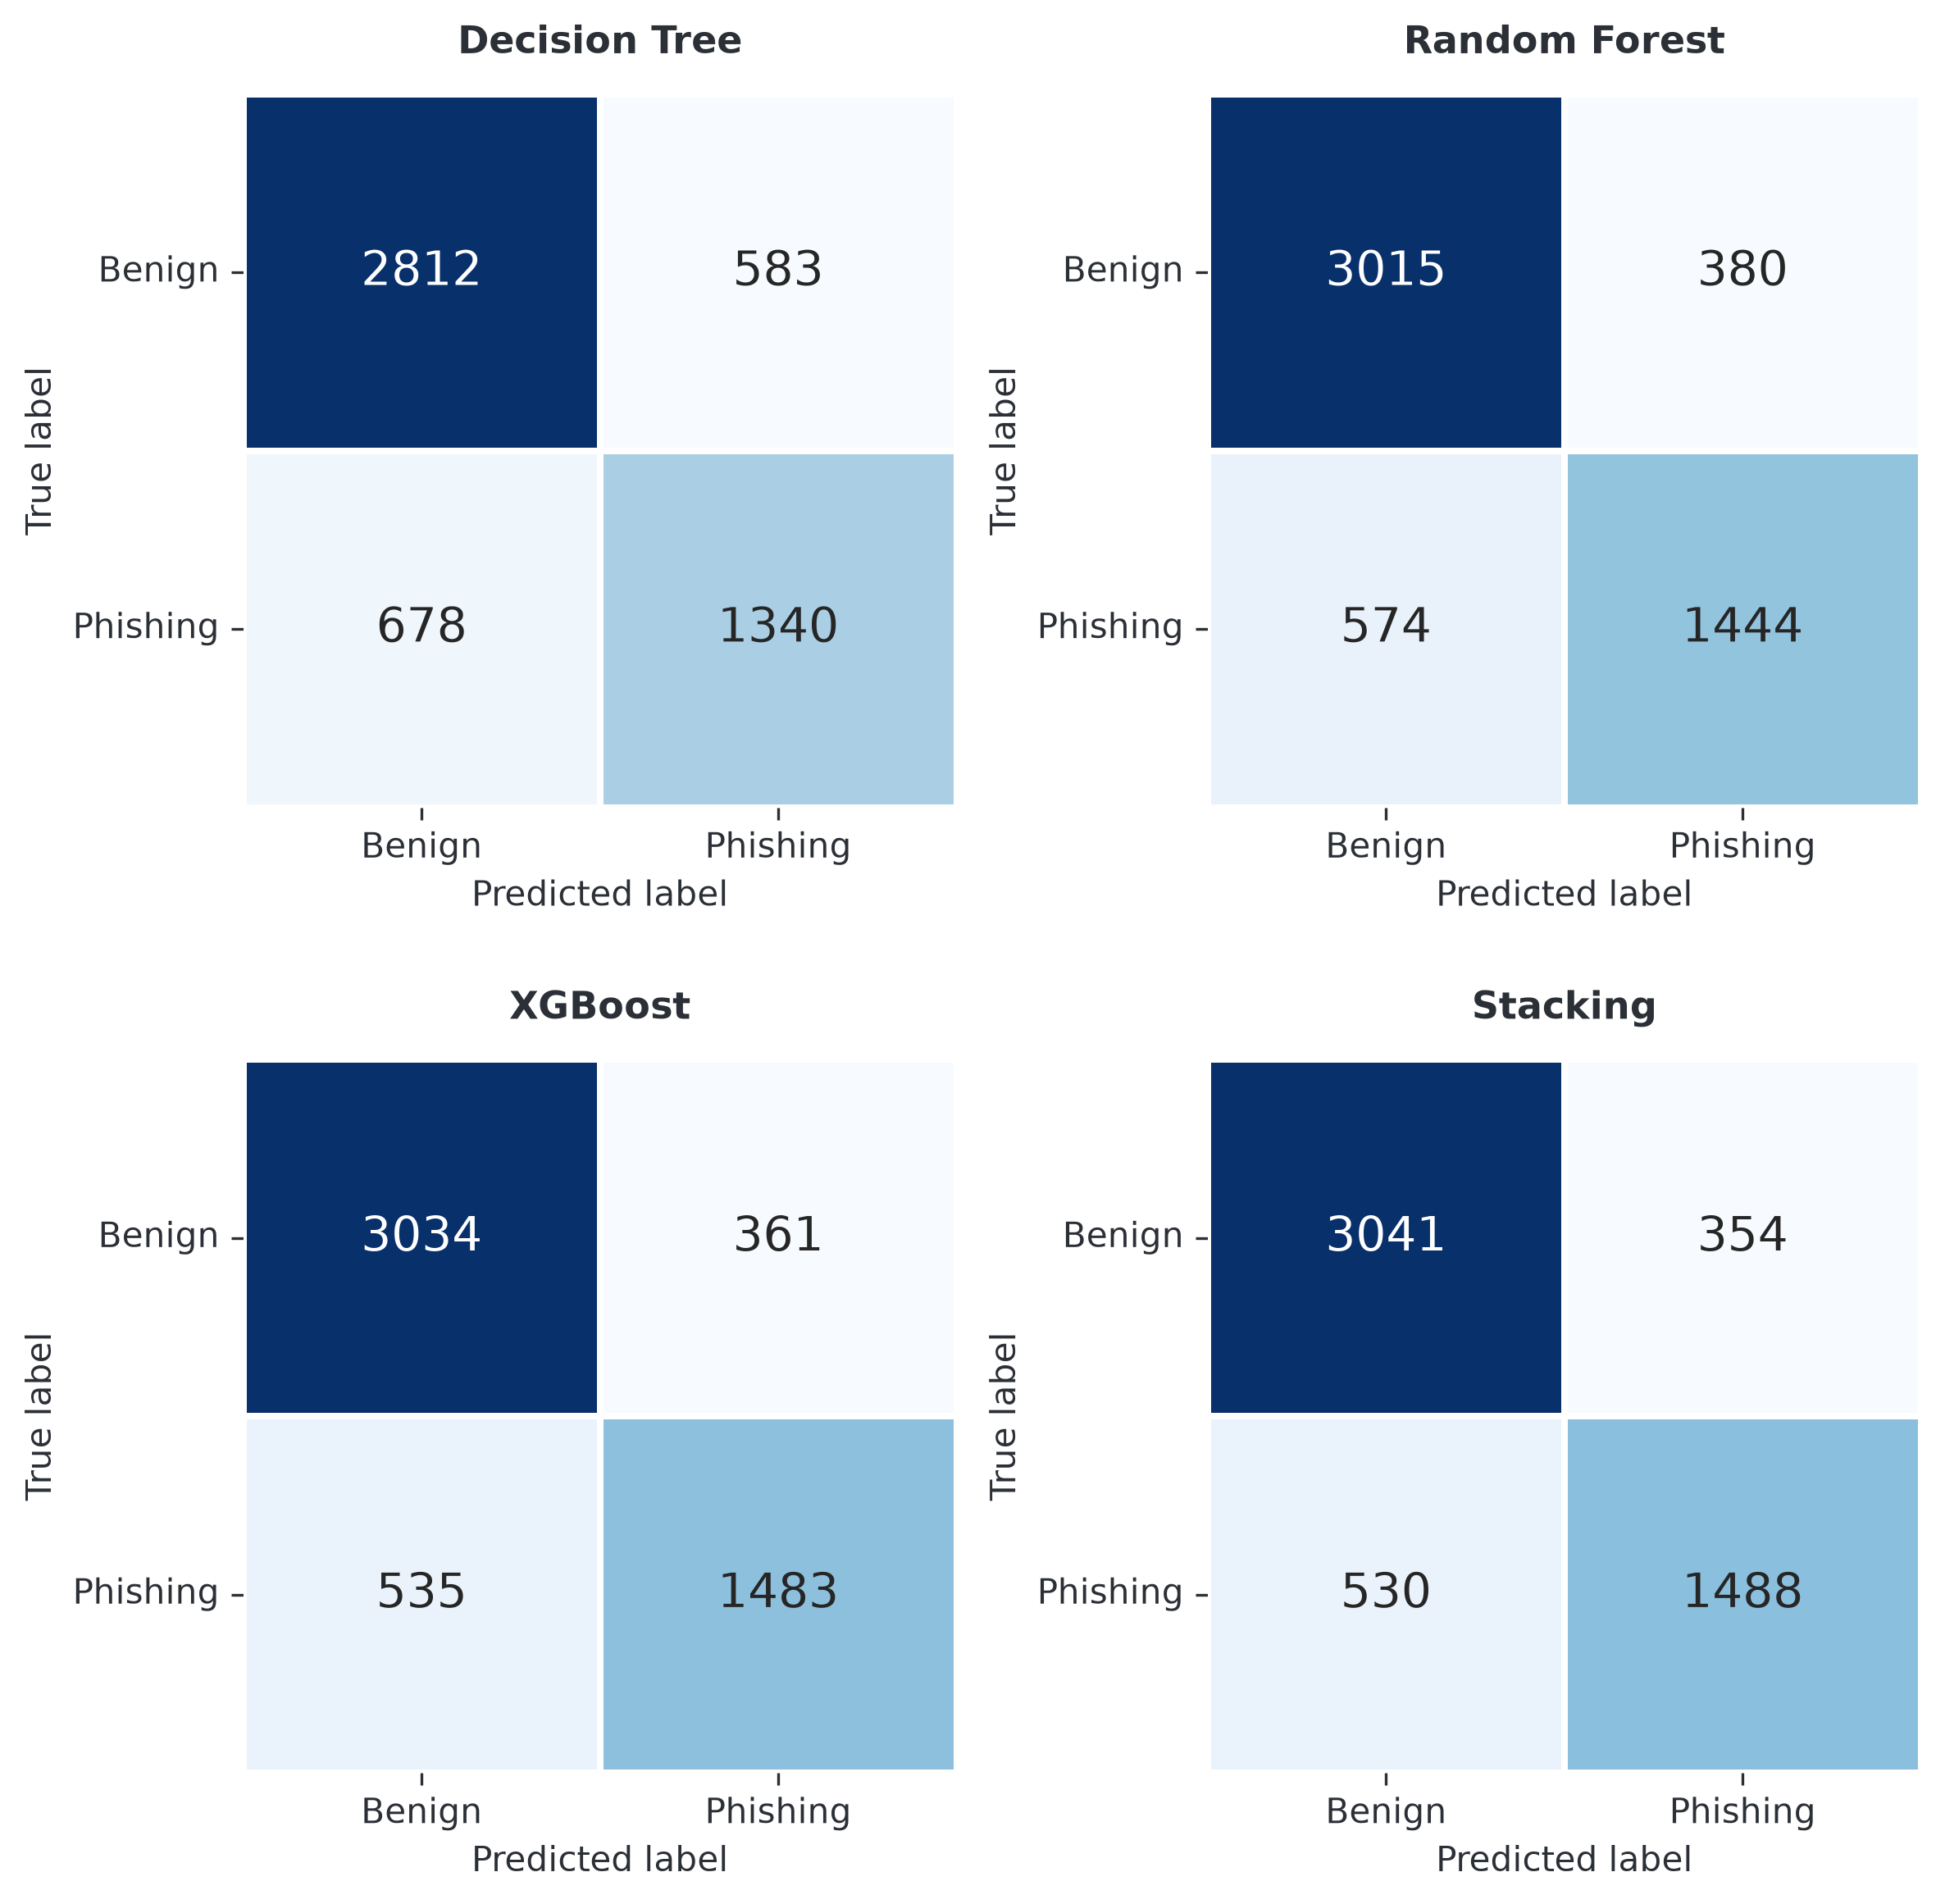

In [21]:
# figures 3-6: 2x2 grid of confusion matrices in a single figure
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for (name, model), ax in zip(models.items(), axes.flatten()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                linewidths=1.5, linecolor="white", annot_kws={"size": 14},
                xticklabels=["Benign", "Phishing"], yticklabels=["Benign", "Phishing"], ax=ax)
    
    ax.tick_params(axis="y", labelrotation=0)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"{MODEL_LABELS[name]}")
plt.tight_layout()
plt.show()

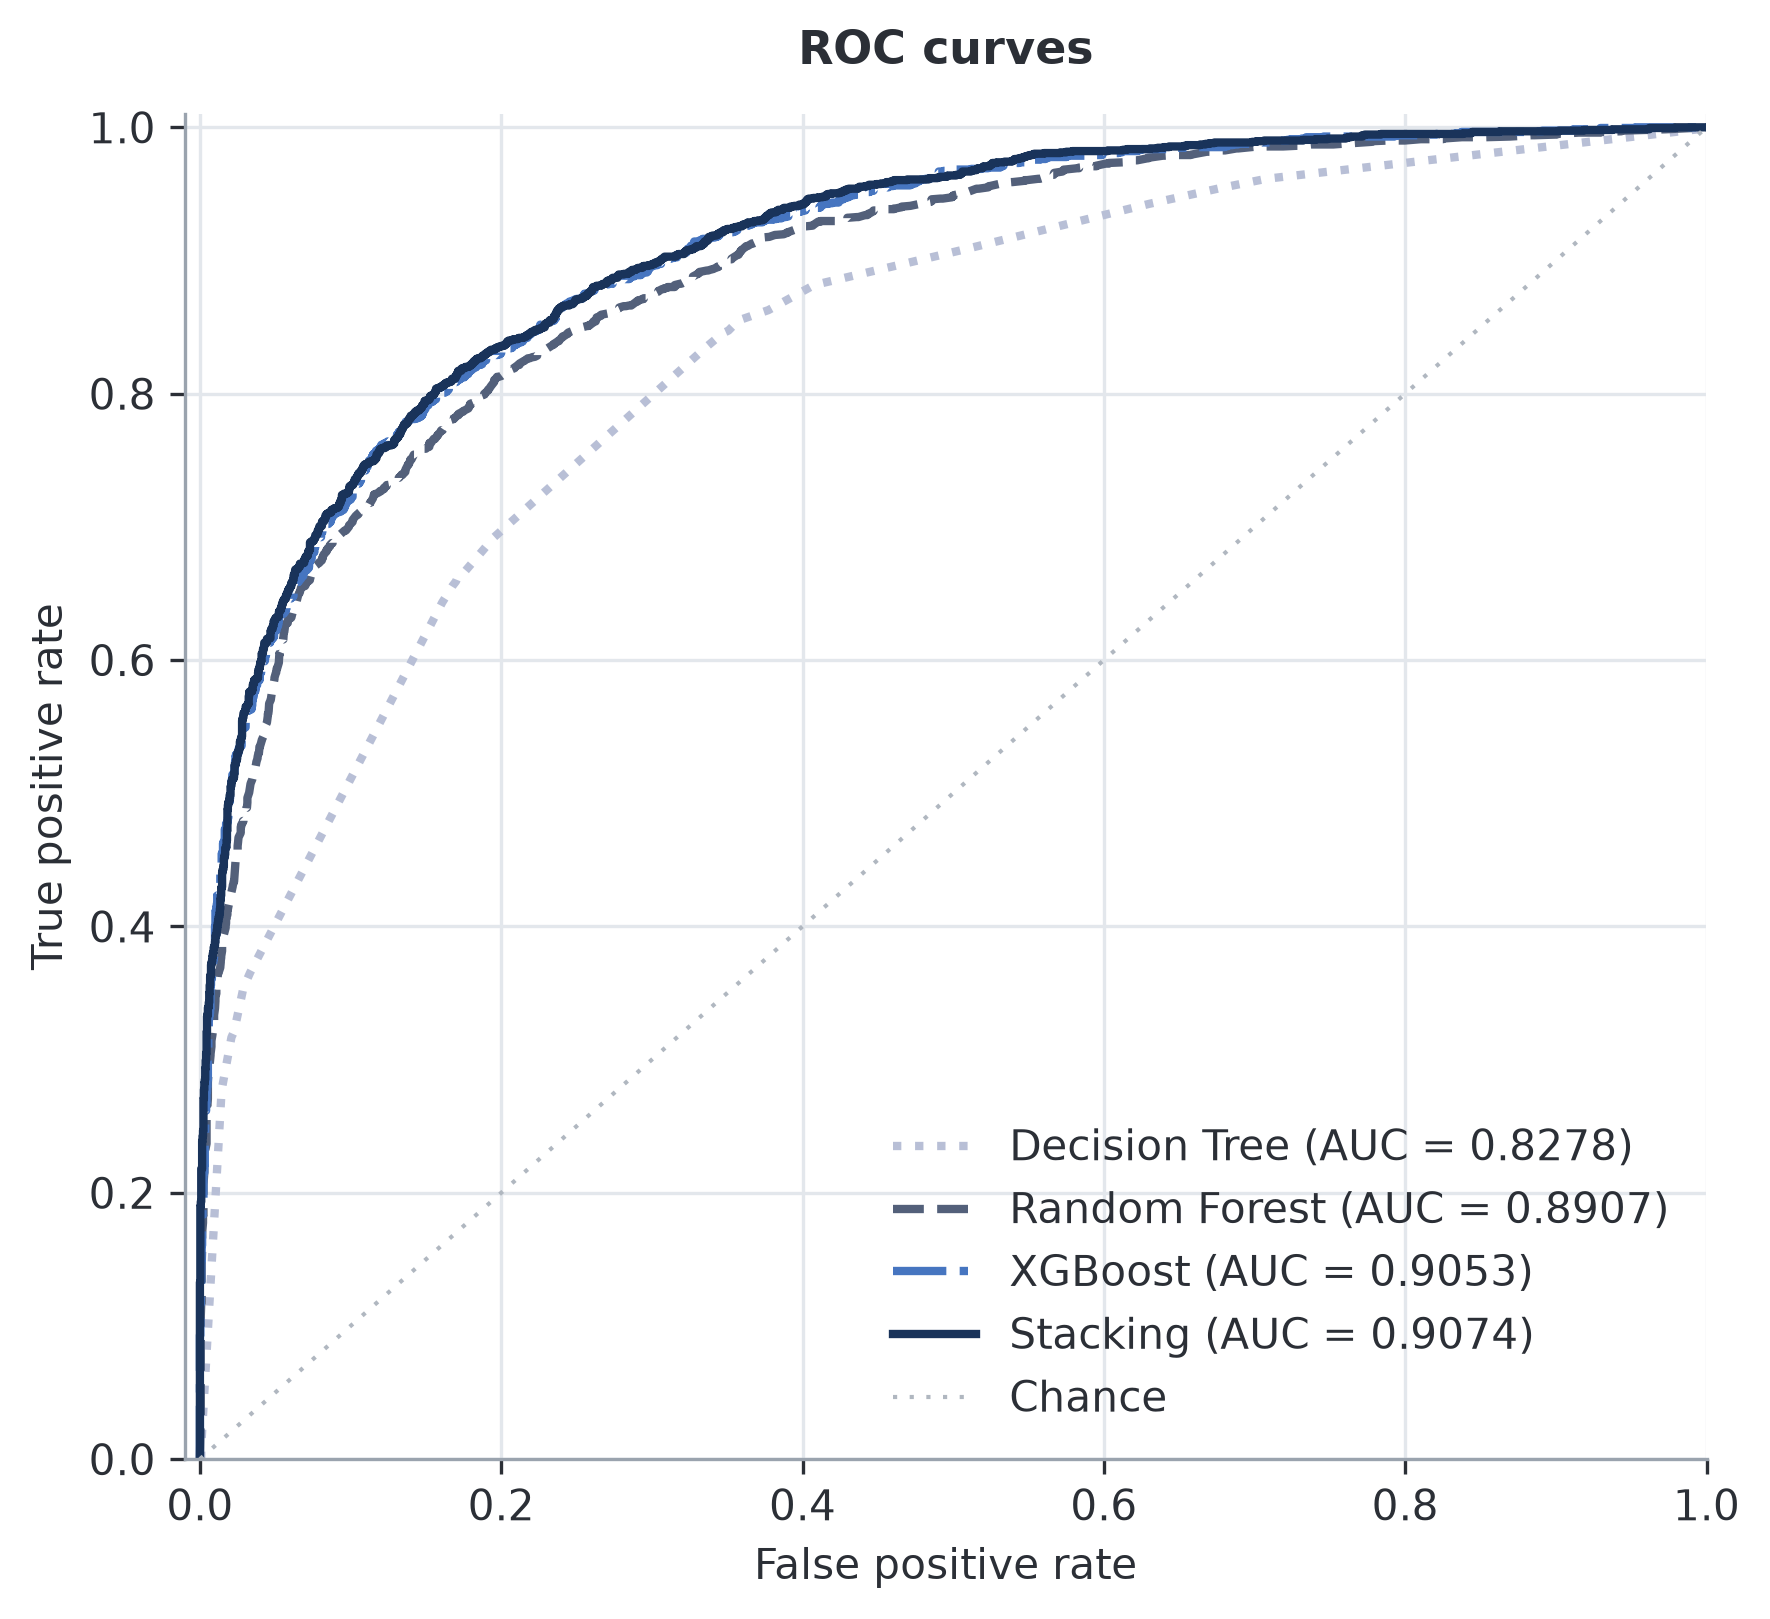

In [22]:
# figure 7: ROC curves (AUC on the held-out test set)
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], ls=MODEL_STYLES[name], lw=2,
            label=f"{MODEL_LABELS[name]} (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], color="#B0B7C0", lw=1, ls=(0, (1, 3)), label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves")
ax.set_xlim(-0.01, 1.0); ax.set_ylim(0, 1.01)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Feature importance per group

In [25]:
rows = []
for name in ["decision_tree", "random_forest", "xgboost"]:
    # 1. Load the fitted model from the file you saved during training
    model_path = f"{MODELS_DIR}/{name}_E2_full.joblib"
    loaded_model = joblib.joblib_load(model_path) if hasattr(joblib, 'joblib_load') else joblib.load(model_path) # standard is joblib.load
    
    # 2. Extract feature importances from the loaded model
    importance = pd.Series(loaded_model.feature_importances_, index=feature_cols)
    importance = importance / importance.sum()
    
    rows.append({
        "model": name, 
        "url": importance[url_cols].sum(),
        "html": importance[html_cols].sum(), 
        "js": importance[js_cols].sum()
    })
    
    if name == "xgboost":
        print("top 10 XGBoost features")
        print(importance.sort_values(ascending=False).head(10).round(4))

group_importance = pd.DataFrame(rows)
group_importance.to_csv(f"{RESULTS_DIR}/group_importance.csv", index=False)
group_importance

top 10 XGBoost features
url_length               0.0304
url_slash_count          0.0284
tfidf_bpe_173            0.0206
html_total_hyperlinks    0.0200
tfidf_bpe_213            0.0159
tfidf_bpe_198            0.0152
tfidf_bpe_151            0.0147
tfidf_bpe_204            0.0143
tfidf_bpe_249            0.0132
url_subdomain_count      0.0121
dtype: float32


,model,url,html,js
0,decision_tree,0.638881,0.253929,0.107189
1,random_forest,0.364977,0.265775,0.369248
2,xgboost,0.099691,0.079805,0.820505
